# RC3SI — Stage 04: Model Training & Validation Comparison

**Goal:** Learn and compare supervised classifiers that distinguish recorded **100% irrigation Line 1 (class 0)** from **30% irrigation Line 3 (class 1)** patterns in the Parma 2023 dataset. These are **treatment/physical-line labels, not plant-stress diagnoses**.

**Input:** your own executed `RC3SI_Stage03_Outputs_v1.zip`. **Output:** `RC3SI_Stage04_Outputs_v1.zip` with training-only fitted models, validation-only ranking, predictions and metadata for Stage 05.

**Protocol:** Three validation candidates each for Logistic Regression, SVM, Random Forest and HistGradientBoosting; Dummy baseline. Model selection by **validation F1** (then validation ROC-AUC as tie-breaker). No test evaluation, test inspection, threshold optimization or fitting on validation rows in Stage 04. Do **not** run all variants on test until final selection in Stage 05.

Run on **CPU**, no GPU necessary. Keep the ZIP and notebook for GitHub and project review.

## Cell 1 — Import packages and set reproducibility seed

In [1]:
import io, json, os, random, zipfile, warnings
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import joblib
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
SEED=42
random.seed(SEED); np.random.seed(SEED)
print('pandas',pd.__version__,'scikit-learn',sklearn.__version__)

pandas 2.2.3 scikit-learn 1.6.1


## Cell 2 — Upload your Stage 03 results ZIP

This code also runs without uploading if the ZIP is already present locally.

In [2]:
SOURCE_ZIP = Path('RC3SI_Stage03_Outputs_v1.zip')
if not SOURCE_ZIP.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        matches = [k for k in uploaded if k.endswith('.zip')]
        if len(matches)!=1:
            raise ValueError('Upload exactly one Stage 03 ZIP file.')
        SOURCE_ZIP = Path(matches[0])
    except ImportError:
        raise FileNotFoundError('Put RC3SI_Stage03_Outputs_v1.zip in the working directory.')
print('Using:',SOURCE_ZIP.name,'size:',SOURCE_ZIP.stat().st_size,'bytes')

Saving RC3SI_Stage03_Outputs_v1.zip to RC3SI_Stage03_Outputs_v1.zip
Using: RC3SI_Stage03_Outputs_v1.zip size: 457587 bytes


## Cell 3 — Read the archived engineered dataset and manifest

In [3]:
with zipfile.ZipFile(SOURCE_ZIP) as archive:
    names=set(archive.namelist())
    assert {'stage03_manifest.json','parma2023_binary_engineered.csv'}.issubset(names), names
    manifest=json.loads(archive.read('stage03_manifest.json'))
    data=pd.read_csv(io.BytesIO(archive.read('parma2023_binary_engineered.csv')))
print('Stage:',manifest['stage'])
print('Rows and columns:',data.shape)
print('Split record counts:',data['split'].value_counts().to_dict())
print('Label semantics:',manifest['classification_target'])

Stage: 03 Feature Engineering and Selection
Rows and columns: (3531, 24)
Split record counts: {'train': 2165, 'test': 706, 'validation': 660}
Label semantics: 100% (0) vs 30% (1) irrigation-assignment pattern, NOT observed physiological stress


## Cell 4 — Validate input schema, selected features, splits and labels

In [4]:
features=list(manifest['features_selected_training_only'])
assert features and len(features)==len(set(features))
assert len(features)==10, 'Inspect unexpected number of selected features'
for forbidden in ['target','line','split','treatment_percent','timestamp','environment_observed_at']:
    assert forbidden not in features, f'Label leakage: {forbidden}'
assert set(features).issubset(data.columns)
assert {'train','validation','test'}.issubset(set(data['split']))
assert set(data['target'].dropna().unique())=={0,1}
assert data[features].notna().all().all(), 'Unexpected missing input features'
assert set(data[data.split=='train']['target'])=={0,1}
assert set(data[data.split=='validation']['target'])=={0,1}
assert not data.duplicated(subset=['line','timestamp']).any(), 'Duplicate line-timestamps'
print('Feature schema OK. Selected features:')
for i,f in enumerate(features,1): print(f' {i:2}. {f}')

Feature schema OK. Selected features:
  1. soil_humidity_lag_1h
  2. soil_humidity_lag_6h
  3. soil_humidity
  4. soil_humidity_lag_3h
  5. soil_humidity_prev_3h_mean
  6. soil_humidity_prev_6h_mean
  7. soil_electrical_conductivity
  8. soil_humidity_change_3h
  9. soil_humidity_change_1h
 10. soil_temperature


## Cell 5 — Isolate TRAIN and VALIDATION partitions only

**Important:** We do not build a test feature matrix or calculate any test metric here.

In [5]:
tr = data.loc[data['split'].eq('train')].copy()
va = data.loc[data['split'].eq('validation')].copy()
X_train = tr[features].copy(); y_train=tr['target'].astype(int).copy()
X_val = va[features].copy(); y_val=va['target'].astype(int).copy()
assert len(X_train)==2165 and len(X_val)==660, 'Dataset counts differ from supplied Stage 03 export; investigate first.'
print('Training records:',len(X_train),'Validation records:',len(X_val))
print('Training classes:',y_train.value_counts().sort_index().to_dict())
print('Validation classes:',y_val.value_counts().sort_index().to_dict())
print('Positive class: treatment 30% line 3 (NOT verified plant stress)')

Training records: 2165 Validation records: 660
Training classes: {0: 1084, 1: 1081}
Validation classes: {0: 330, 1: 330}
Positive class: treatment 30% line 3 (NOT verified plant stress)


## Cell 6 — Set evaluation measures and a consistent 0.5 decision threshold

Accuracy, balanced accuracy, precision, recall, F1, ROC-AUC and PR-AUC are calculated on **validation only**. A fixed threshold prevents retrospective threshold tuning; AUC uses probability scores.

In [6]:
def validation_metrics(estimator, X, y):
    scores=estimator.predict_proba(X)[:,1]
    pred=(scores>=0.5).astype(int)
    return dict(accuracy=accuracy_score(y,pred),
                balanced_accuracy=balanced_accuracy_score(y,pred),
                precision=precision_score(y,pred,zero_division=0),
                recall=recall_score(y,pred,zero_division=0),
                f1=f1_score(y,pred,zero_division=0),
                roc_auc=roc_auc_score(y,scores),
                pr_auc=average_precision_score(y,scores))
print('Metrics defined. All computed outputs below are VALIDATION only.')

Metrics defined. All computed outputs below are VALIDATION only.


## Cell 7 — Define a trivial Dummy baseline

In [7]:
dummy=DummyClassifier(strategy='prior')
dummy.fit(X_train,y_train)
dummy_scores=validation_metrics(dummy,X_val,y_val)
display(pd.DataFrame([{'model':'Dummy (training prior)',**dummy_scores}]).round(4))

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
0,Dummy (training prior),0.5,0.5,0.0,0.0,0.0,0.5,0.5


## Cell 8 — Define classifier pipelines (training-only scaling)

For Logistic Regression and SVM, the `StandardScaler` is inside the estimator pipeline so **only training data** determines its parameters. Tree classifiers do not need scaling. For SVM, `probability=True` fits training-only internal probability calibration; it does not use validation or test records. It is not a time-aware calibrator, which is a limitation to disclose.

In [8]:
MODEL_GRIDS = {
 'Logistic Regression': [
    {'C':0.1}, {'C':1.0}, {'C':10.0}],
 'SVM (RBF)': [
    {'C':0.1,'gamma':'scale'}, {'C':1.0,'gamma':'scale'}, {'C':10.0,'gamma':'scale'}],
 'Random Forest': [
    {'n_estimators':150,'max_depth':5},
    {'n_estimators':150,'max_depth':10},
    {'n_estimators':150,'max_depth':None}],
 'HistGradientBoosting': [
    {'max_iter':100,'learning_rate':0.05,'max_leaf_nodes':15},
    {'max_iter':100,'learning_rate':0.1,'max_leaf_nodes':15},
    {'max_iter':150,'learning_rate':0.05,'max_leaf_nodes':31}],
}
def make_model(name, params):
    if name=='Logistic Regression':
        return Pipeline([('imputer', SimpleImputer(strategy='median')),
                         ('scaler',StandardScaler()),
                         ('classifier',LogisticRegression(max_iter=2000,random_state=SEED,**params))])
    if name=='SVM (RBF)':
        return Pipeline([('imputer', SimpleImputer(strategy='median')),
                         ('scaler',StandardScaler()),
                         ('classifier',SVC(kernel='rbf',probability=True,random_state=SEED,**params))])
    if name=='Random Forest':
        return Pipeline([('imputer', SimpleImputer(strategy='median')),
                         ('classifier',RandomForestClassifier(random_state=SEED,n_jobs=-1,
                                                             min_samples_leaf=5,**params))])
    if name=='HistGradientBoosting':
        return Pipeline([('imputer', SimpleImputer(strategy='median')),
                         ('classifier',HistGradientBoostingClassifier(random_state=SEED,
                                                                     min_samples_leaf=20,**params))])
    raise ValueError(name)
print('3 candidates x 4 classifier families =', sum(map(len,MODEL_GRIDS.values())),'training-only fits')

3 candidates x 4 classifier families = 12 training-only fits


## Cell 9 — Train every predefined candidate and evaluate against validation

One fair small search budget: **three fixed configurations per trainable classifier family**. We record all experiments, not just the best.

In [9]:
candidate_results=[]
fitted={}
for name, configurations in MODEL_GRIDS.items():
    for index, params in enumerate(configurations, start=1):
        model=make_model(name,params)
        model.fit(X_train,y_train)
        metrics=validation_metrics(model,X_val,y_val)
        tag=f'{name} | config {index}'
        candidate_results.append({'model':name,'configuration':index,'params':json.dumps(params,sort_keys=True),**metrics})
        fitted[(name,index)]=model
        print(f'{tag:35s} F1={metrics["f1"]:.4f} ROC-AUC={metrics["roc_auc"]:.4f}')
results=pd.DataFrame(candidate_results)
print('Completed training-only candidate fits:',len(fitted))

Logistic Regression | config 1      F1=0.1717 ROC-AUC=0.9255
Logistic Regression | config 2      F1=0.1667 ROC-AUC=0.9230
Logistic Regression | config 3      F1=0.1667 ROC-AUC=0.9222
SVM (RBF) | config 1                F1=0.8234 ROC-AUC=0.9417
SVM (RBF) | config 2                F1=0.8190 ROC-AUC=0.9248
SVM (RBF) | config 3                F1=0.8032 ROC-AUC=0.8618
Random Forest | config 1            F1=0.8126 ROC-AUC=0.9070
Random Forest | config 2            F1=0.8576 ROC-AUC=0.9382
Random Forest | config 3            F1=0.8450 ROC-AUC=0.9344
HistGradientBoosting | config 1     F1=0.8072 ROC-AUC=0.9476
HistGradientBoosting | config 2     F1=0.8683 ROC-AUC=0.9715
HistGradientBoosting | config 3     F1=0.8709 ROC-AUC=0.9791
Completed training-only candidate fits: 12


## Cell 10 — Show the full validation comparison table

In [10]:
display(results.sort_values(['f1','roc_auc'],ascending=[False,False]).round(4).reset_index(drop=True))

,model,configuration,params,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
0,HistGradientBoosting,3,"{""learning_rate"": 0.05, ""max_iter"": 150, ""max_...",0.8818,0.8818,0.9599,0.7970,0.8709,0.9791,0.9793
1,HistGradientBoosting,2,"{""learning_rate"": 0.1, ""max_iter"": 100, ""max_l...",0.8773,0.8773,0.9368,0.8091,0.8683,0.9715,0.9722
2,Random Forest,2,"{""max_depth"": 10, ""n_estimators"": 150}",0.8591,0.8591,0.8669,0.8485,0.8576,0.9382,0.9355
3,Random Forest,3,"{""max_depth"": null, ""n_estimators"": 150}",0.8455,0.8455,0.8476,0.8424,0.8450,0.9344,0.9334
4,SVM (RBF),1,"{""C"": 0.1, ""gamma"": ""scale""}",0.8121,0.8121,0.7769,0.8758,0.8234,0.9417,0.9509
5,SVM (RBF),2,"{""C"": 1.0, ""gamma"": ""scale""}",0.7985,0.7985,0.7432,0.9121,0.8190,0.9248,0.9234
6,Random Forest,1,"{""max_depth"": 5, ""n_estimators"": 150}",0.7924,0.7924,0.7406,0.9000,0.8126,0.9070,0.9061
7,HistGradientBoosting,1,"{""learning_rate"": 0.05, ""max_iter"": 100, ""max_...",0.8227,0.8227,0.8845,0.7424,0.8072,0.9476,0.9452
8,SVM (RBF),3,"{""C"": 10.0, ""gamma"": ""scale""}",0.7742,0.7742,0.7119,0.9212,0.8032,0.8618,0.8401
9,Logistic Regression,1,"{""C"": 0.1}",0.5470,0.5470,1.0000,0.0939,0.1717,0.9255,0.9337


## Cell 11 — Pick best configuration of each model family on validation

In [11]:
family_best = (results.sort_values(['f1','roc_auc','configuration'],ascending=[False,False,True])
               .drop_duplicates('model').sort_values(['f1','roc_auc'],ascending=[False,False])
               .reset_index(drop=True))
baseline_row={'model':'Dummy (training prior)','configuration':0,'params':'{}',**dummy_scores}
family_comparison=pd.concat([pd.DataFrame([baseline_row]),family_best],ignore_index=True)
display(family_comparison.round(4))

,model,configuration,params,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
0,Dummy (training prior),0,{},0.5000,0.5000,0.0000,0.0000,0.0000,0.5000,0.5000
1,HistGradientBoosting,3,"{""learning_rate"": 0.05, ""max_iter"": 150, ""max_...",0.8818,0.8818,0.9599,0.7970,0.8709,0.9791,0.9793
2,Random Forest,2,"{""max_depth"": 10, ""n_estimators"": 150}",0.8591,0.8591,0.8669,0.8485,0.8576,0.9382,0.9355
3,SVM (RBF),1,"{""C"": 0.1, ""gamma"": ""scale""}",0.8121,0.8121,0.7769,0.8758,0.8234,0.9417,0.9509
4,Logistic Regression,1,"{""C"": 0.1}",0.5470,0.5470,1.0000,0.0939,0.1717,0.9255,0.9337


## Cell 12 — Choose one final classifier for the future held-out test

Only the selected fitted **training-only** model is exported. We do not refit using validation, and we never select a different model based on Stage 05 test performance.

In [12]:
selected=family_best.iloc[0]
selected_name=str(selected['model']); selected_config=int(selected['configuration'])
selected_model=fitted[(selected_name,selected_config)]
print('Selected classifier family:',selected_name)
print('Selected config:',selected_config)
print('Selection metric: validation F1, ROC-AUC as tie-breaker')
print('Validation F1:',round(float(selected['f1']),4))
print('This is validation model selection, not final/test performance.')

Selected classifier family: HistGradientBoosting
Selected config: 3
Selection metric: validation F1, ROC-AUC as tie-breaker
Validation F1: 0.8709
This is validation model selection, not final/test performance.


## Cell 13 — Visualize one best candidate from each family

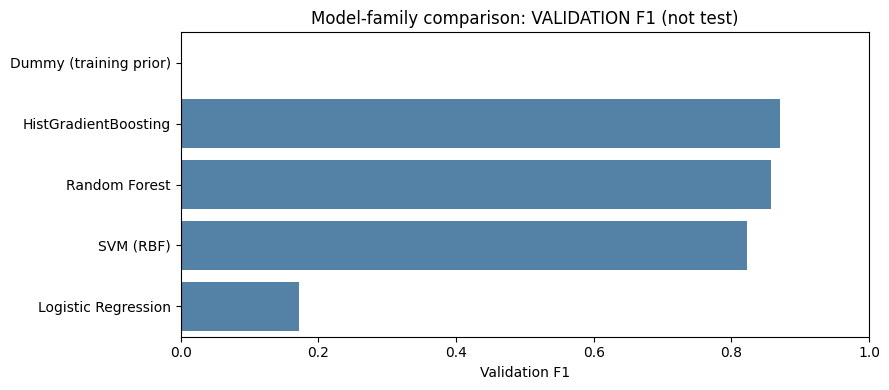

In [13]:
plt.figure(figsize=(9,4))
sns.barplot(data=family_comparison,y='model',x='f1',color='steelblue')
plt.xlim(0,1.0); plt.title('Model-family comparison: VALIDATION F1 (not test)')
plt.xlabel('Validation F1');plt.ylabel('');plt.tight_layout();plt.show()

## Cell 14 — Visualize validation confusion matrix of selected model

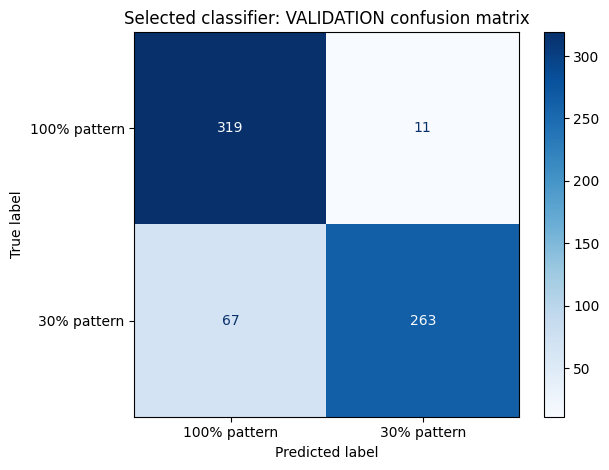

In [14]:
validation_predictions=(selected_model.predict_proba(X_val)[:,1]>=0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(y_val,validation_predictions,display_labels=['100% pattern','30% pattern'],cmap='Blues')
plt.title('Selected classifier: VALIDATION confusion matrix')
plt.tight_layout();plt.show()

## Cell 15 — ROC and precision–recall curves (validation ONLY)

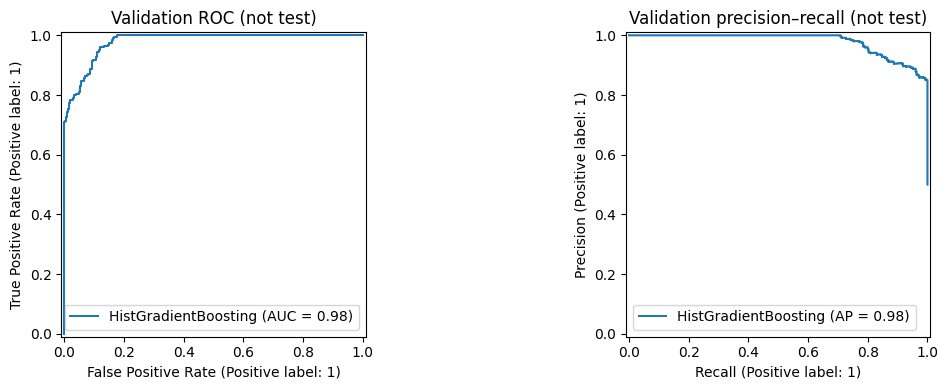

In [15]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
RocCurveDisplay.from_estimator(selected_model,X_val,y_val,ax=axs[0],name=selected_name)
PrecisionRecallDisplay.from_estimator(selected_model,X_val,y_val,ax=axs[1],name=selected_name)
axs[0].set_title('Validation ROC (not test)')
axs[1].set_title('Validation precision–recall (not test)')
plt.tight_layout();plt.show()

## Cell 16 — Sanity check model pipeline and forbidden identifiers

In [16]:
assert all(c not in features for c in ['line','target','treatment_percent','split'])
assert len(fitted)==12
assert set(results['model'])==set(MODEL_GRIDS)
assert selected_model.n_features_in_==len(features)
assert not pd.isna(results[['accuracy','precision','recall','f1','roc_auc','pr_auc']].to_numpy()).any()
print('Checks passed: no treatment/line identifier among predictors.')
print('Still important: physical-line and treatment are confounded in this single-year dataset.')
print('Testing remains untouched. Accuracy is within-season known-line discrimination.')

Checks passed: no treatment/line identifier among predictors.
Still important: physical-line and treatment are confounded in this single-year dataset.
Testing remains untouched. Accuracy is within-season known-line discrimination.


## Cell 17 — Save model, complete validation report and provenance

In [17]:
OUT=Path('rc3si_stage04_outputs');OUT.mkdir(exist_ok=True)
model_filename='selected_validation_model_train_only.joblib'
joblib.dump(selected_model,OUT/model_filename)
results.to_csv(OUT/'validation_all_candidates.csv',index=False)
family_comparison.to_csv(OUT/'validation_family_comparison.csv',index=False)
validation_export=va[['timestamp','line','split','target']].copy()
validation_export['predicted_30percent_probability']=selected_model.predict_proba(X_val)[:,1]
validation_export['predicted_label_at_0_5']=validation_predictions
validation_export.to_csv(OUT/'validation_selected_predictions.csv',index=False)
output_metadata={
    'project':'RC3SI','stage':'04 Model Training and Validation Comparison',
    'input_archive':SOURCE_ZIP.name,'input_stage03_manifest':manifest,
    'target':'0=100% line1 treatment pattern; 1=30% line3 treatment pattern; not physiological stress',
    'training_rows':int(len(tr)),'validation_rows':int(len(va)),
    'test_evaluated':False,'trained_on':['train'],'model_selected_on':'validation',
    'feature_names_ordered':features,
    'candidate_search_budget_per_family':3,
    'model_families':list(MODEL_GRIDS),
    'selection_primary_metric':'validation_f1_at_fixed_threshold_0.5',
    'selection_tiebreaker':'validation_roc_auc',
    'selected_model_family':selected_name,'selected_configuration_index':selected_config,
    'selected_parameters':json.loads(selected['params']),
    'selected_validation_metrics':{k:float(selected[k]) for k in dummy_scores},
    'selected_model_file':model_filename,'prediction_threshold':0.5,
    'python_sklearn_version':sklearn.__version__,
    'scientific_limitations':['treatment vs physical line confounding','one farm one year','temporal autocorrelation',
                              'no independent physiology or early warning ground truth',
                              'validation chosen model is not unbiased held-out performance',
                              'SVC probability calibration is within training but not time-aware']}
(OUT/'stage04_manifest.json').write_text(json.dumps(output_metadata,indent=2),encoding='utf8')
print('Saved model and reports to',OUT)
print('Model:',model_filename)

Saved model and reports to rc3si_stage04_outputs
Model: selected_validation_model_train_only.joblib


## Cell 18 — Package and download Stage 04 outputs

In [18]:
OUTPUT_ZIP=Path('RC3SI_Stage04_Outputs_v1.zip')
with zipfile.ZipFile(OUTPUT_ZIP,'w',compression=zipfile.ZIP_DEFLATED) as out:
    for path in sorted(OUT.iterdir()):
        out.write(path,arcname=path.name)
with zipfile.ZipFile(OUTPUT_ZIP) as out:
    print('Output files:',out.namelist())
print('ZIP size (KB):',round(OUTPUT_ZIP.stat().st_size/1024,1))
try:
    from google.colab import files
    files.download(str(OUTPUT_ZIP))
except ImportError:
    print('Local output available:',OUTPUT_ZIP.resolve())

Output files: ['selected_validation_model_train_only.joblib', 'stage04_manifest.json', 'validation_all_candidates.csv', 'validation_family_comparison.csv', 'validation_selected_predictions.csv']
ZIP size (KB): 204.6


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What you should submit after running Stage 04

1. The **executed** `RC3SI_Stage04_Model_Training_Comparison_v1.ipynb` downloaded from Colab.
2. The **output** `RC3SI_Stage04_Outputs_v1.zip` containing your own trained model and validation reports.

We'll review the real validation results before Stage 05's **single held-out test evaluation**. Never write “stress accuracy” or “early warning” based only on these line-based labels. The held-out test still contains the *same lines* at later dates; it does not establish generalization to unseen treatment lines or farms.